# 7. Exploración de titulares

El corpus se analiza por disponibilidad, fuente y características léxicas. Los tópicos se aprenden automáticamente; no se asignan categorías temáticas manuales.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
panel = pq.read_table(ROOT/'data/processed/panel_horario.parquet', filters=[('inicio','<',pd.Timestamp('2022-01-01',tz='America/Bogota'))]).to_pandas()
assert panel.index.max() < pd.Timestamp('2022-01-01',tz='America/Bogota')
assert panel.index.is_monotonic_increasing and panel.index.is_unique
y = panel['y_demanda_real_kwh']
gwh = y / 1e6
registro = json.loads((ROOT/'data/processed/feature_registry.json').read_text(encoding='utf-8'))


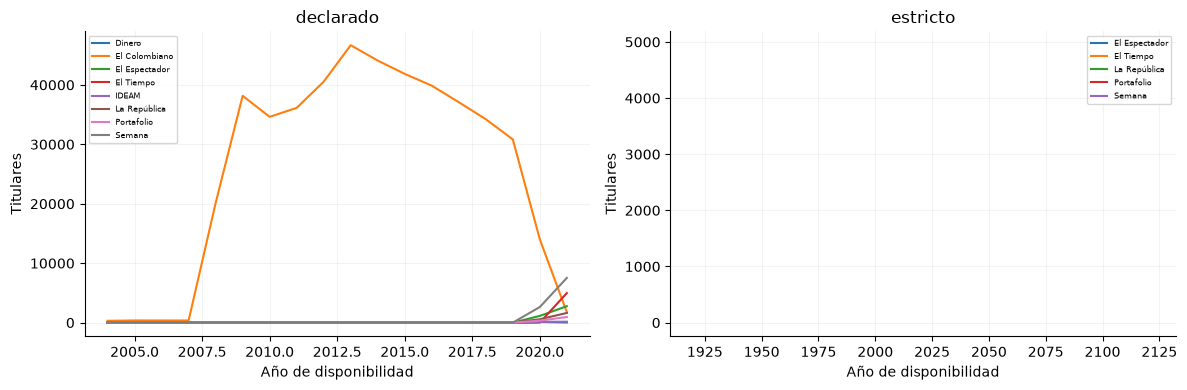

In [2]:
coberturas={}
for escenario in ['declarado','estricto']:
    c=pd.read_csv(ROOT/f'data/processed/cobertura_titulares_{escenario}.csv',index_col=0); c.index=c.index.astype(int); coberturas[escenario]=c.loc[c.index<2022]
fig,axes=plt.subplots(1,2,figsize=(12,4));
for ax,(escenario,c) in zip(axes,coberturas.items()):
    c.plot(ax=ax); ax.set(title=escenario,xlabel='Año de disponibilidad',ylabel='Titulares'); ax.legend(fontsize=6)
fig.tight_layout(); display(fig); plt.close(fig); total_declarado=int(coberturas['declarado'].sum().sum()); total_estricto=int(coberturas['estricto'].sum().sum())

Desarrollo contiene 484,289 registros en el escenario declarado y 5,272 en el estricto. Son escenarios alternativos, no conjuntos para sumar. Las diferencias de cobertura limitan comparaciones por fuente y tiempo; ausencia de registros recuperados no equivale a ausencia de publicación.

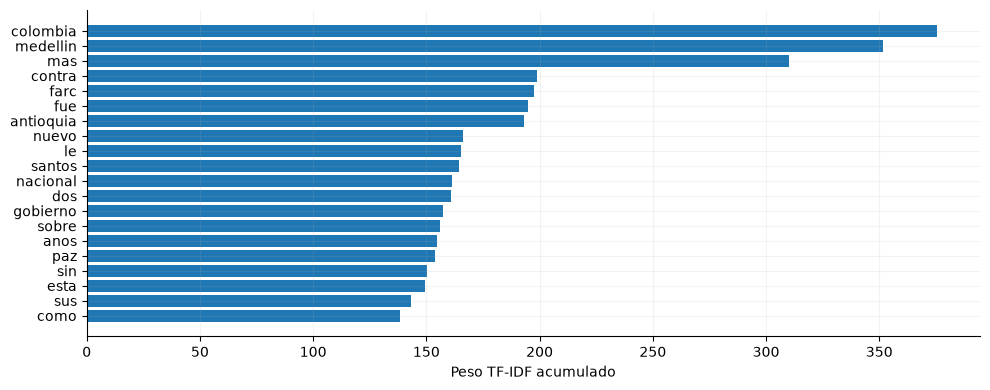

In [3]:
tit=pq.read_table(ROOT/'data/raw/noticias/titulares.parquet',columns=['source','titular','available_at_assumed','quarantined'],filters=[('available_at_assumed','<','2018-01-01'),('available_at_assumed','>=','2000-01-01'),('quarantined','==',False)]).to_pandas(); tit=tit[tit.titular.notna() & tit.titular.str.strip().ne('')]; muestra=tit.sample(min(30000,len(tit)),random_state=11037); from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
vectorizador=TfidfVectorizer(lowercase=True,strip_accents='unicode',min_df=10,max_df=.8,max_features=6000,stop_words=['de','la','el','en','y','a','los','del','las','un','una','por','para','con','que','se','al','su','es','no','lo']); X=vectorizador.fit_transform(muestra.titular); nmf=NMF(n_components=6,random_state=11037,max_iter=400); W=nmf.fit_transform(X); palabras=vectorizador.get_feature_names_out(); frecuencia=np.asarray(X.sum(axis=0)).ravel(); top=np.argsort(frecuencia)[-20:]; fig,ax=plt.subplots(); ax.barh(palabras[top],frecuencia[top]); ax.set_xlabel('Peso TF-IDF acumulado'); fig.tight_layout(); display(fig); plt.close(fig); n_textos=len(tit); n_muestra=len(muestra); termino=palabras[top[-1]]

El vocabulario se ajusta con 30,000 titulares de una población de 380,541 registros declarados anteriores a 2018. «colombia» concentra el mayor peso TF-IDF acumulado; esta medida refleja composición léxica y no frecuencia bruta ni señal predictiva de demanda.

,topico,terminos
0,T1,medellin · bogota · autopista · centro · metro...
1,T2,colombia · mundial · seleccion · venezuela · e...
2,T3,mas · mundo · anos · menos · millones · pais ·...
3,T4,articulo · prueba · sobre · elecciones · sin ·...
4,T5,caricatura · encabezado · 2010 · 2013 · 2011 ·...
5,T6,farc · contra · santos · paz · antioquia · gob...


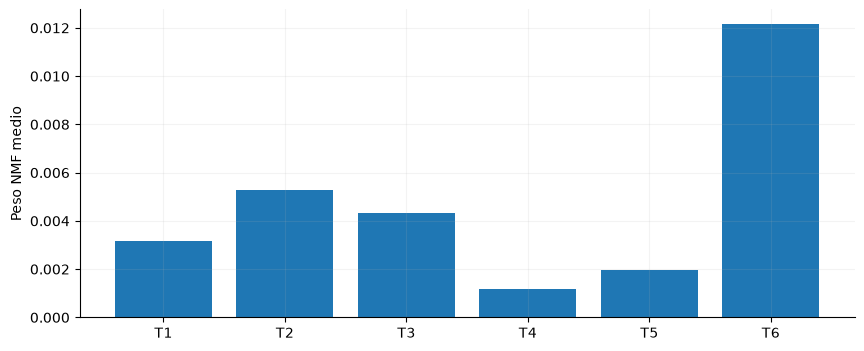

In [4]:
filas=[]
for i,componente in enumerate(nmf.components_):
    filas.append({'topico':f'T{i+1}','terminos':' · '.join(palabras[np.argsort(componente)[-8:][::-1]]),'peso_medio':float(W[:,i].mean())})
display(pd.DataFrame(filas)[['topico','terminos']]); fig,ax=plt.subplots(); ax.bar([r['topico'] for r in filas],[r['peso_medio'] for r in filas]); ax.set_ylabel('Peso NMF medio'); display(fig); plt.close(fig); dominante=filas[int(np.argmax([r['peso_medio'] for r in filas]))]['topico']

T6 presenta el mayor peso medio en la muestra de ajuste. Los términos de la tabla definen componentes aprendidas, no etiquetas editoriales. El predominio de una componente puede reflejar concentración de fuentes o prácticas del archivo, sin demostrar anticipación de la demanda.

**Decisión.** Ajustar vocabulario y tópicos sólo con entrenamiento y congelarlos para su proyección.

**Impacto.** Evita incorporar el vocabulario posterior al ajuste.

**Riesgo.** La disponibilidad declarada no certifica la versión histórica exacta del titular.

## Cobertura mensual, longitud y repetición

El corpus de desarrollo incluye todos los titulares elegibles con disponibilidad declarada anterior a 2022; los registros en cuarentena y los encabezados vacíos quedan excluidos. El ajuste léxico inicial permanece limitado a 2000–2017. La normalización de duplicados aplica Unicode NFKC, minúsculas y eliminación de puntuación y espacios redundantes, conservando las letras acentuadas. Una repetición entre fuentes no se elimina automáticamente.

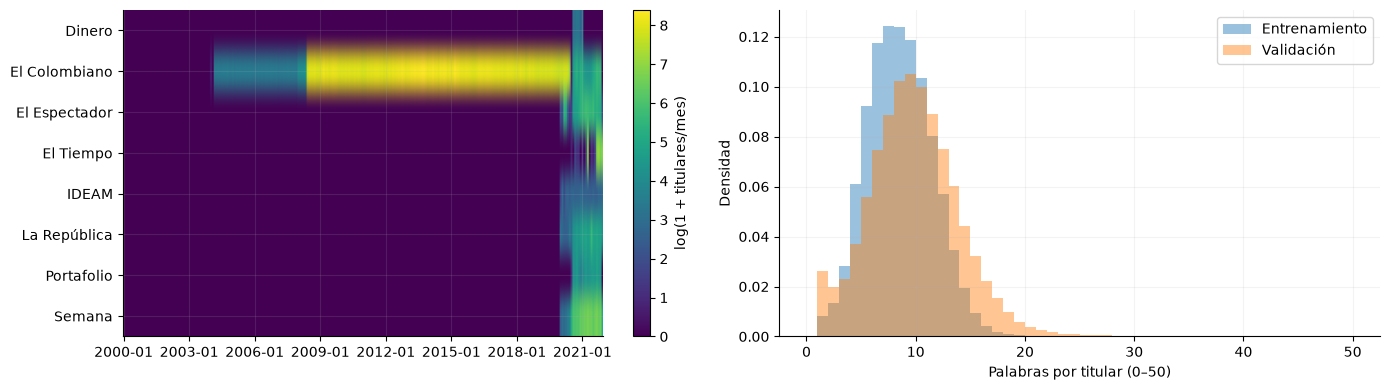

In [5]:
import re,unicodedata
texto=pq.read_table(ROOT/'data/raw/noticias/titulares.parquet',
    columns=['id','source','titular','available_at_assumed','quarantined'],
    filters=[('available_at_assumed','>=','2000-01-01'),('available_at_assumed','<','2022-01-02'),('quarantined','==',False)]).to_pandas()
texto=texto[texto.titular.notna() & texto.titular.str.strip().ne('')].copy()
texto['fecha']=pd.to_datetime(texto.available_at_assumed,utc=True,format='ISO8601').dt.tz_convert('America/Bogota')
texto=texto[(texto.fecha>=pd.Timestamp('2000-01-01',tz='America/Bogota')) & (texto.fecha<pd.Timestamp('2022-01-01',tz='America/Bogota'))].copy()
texto=texto.sort_values(['fecha','source','id'],kind='stable').reset_index(drop=True)
def normalizar_titulo(s):
    s=unicodedata.normalize('NFKC',s).lower()
    return re.sub(r'\s+',' ',re.sub(r'[^\w\s]',' ',s)).strip()
texto['normalizado']=texto.titular.map(normalizar_titulo)
texto['n_palabras']=texto.normalizado.str.split().str.len()
texto['repetido_exacto']=texto.duplicated(['source','titular'],keep='first')
texto['repetido_normalizado']=texto.duplicated(['source','normalizado'],keep='first')
texto['mes']=texto.fecha.dt.tz_localize(None).dt.to_period('M')
texto['periodo']=np.where(texto.fecha.dt.year<2018,'Entrenamiento','Validación')
cob_mes=pd.crosstab(texto.mes,texto.source).reindex(pd.period_range('2000-01','2021-12',freq='M'),fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(14,4))
im=axes[0].imshow(np.log1p(cob_mes.T.to_numpy()),aspect='auto',cmap='viridis')
axes[0].set(yticks=range(len(cob_mes.columns)),yticklabels=cob_mes.columns,
    xticks=np.arange(0,len(cob_mes),36),xticklabels=[str(x) for x in cob_mes.index[::36]])
fig.colorbar(im,ax=axes[0],label='log(1 + titulares/mes)')
for periodo,datos in texto.groupby('periodo'):
    axes[1].hist(datos.n_palabras,bins=np.arange(0,51),density=True,alpha=.45,label=periodo)
axes[1].set(xlabel='Palabras por titular (0–50)',ylabel='Densidad'); axes[1].legend()
fig.tight_layout(); display(fig); plt.close(fig)
n_desarrollo=len(texto); longitud_mediana=float(texto.n_palabras.median())
sin_cobertura=int((cob_mes.sum(axis=1)==0).sum()); cola_larga=int((texto.n_palabras>50).sum())


Se analizan 484,289 titulares, con mediana de 8 palabras. Hay 49 meses sin registros recuperados en ninguna fuente; no equivalen a meses sin publicaciones. El histograma muestra hasta 50 palabras y deja fuera 1 encabezados más extensos. La matriz distingue vacíos del archivo de aumentos de volumen asociados a nuevas fuentes.

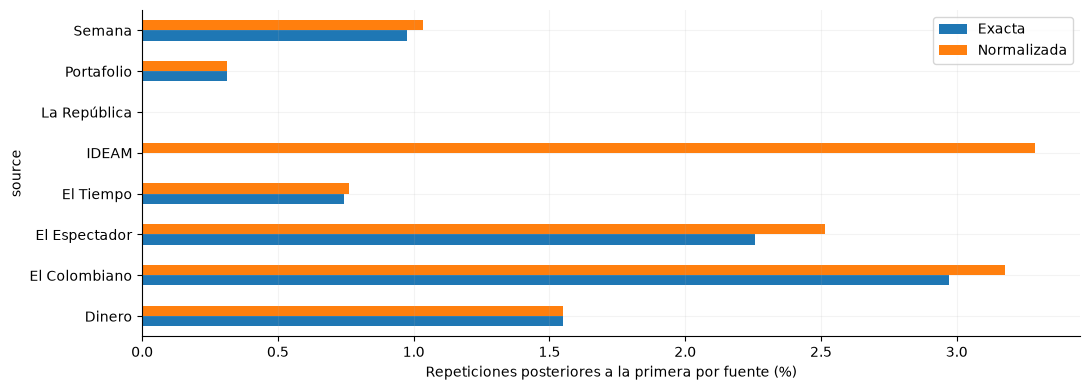

In [6]:
repeticion=texto.groupby('source')[['repetido_exacto','repetido_normalizado']].mean()*100
fig,ax=plt.subplots(figsize=(11,4))
repeticion.rename(columns={'repetido_exacto':'Exacta','repetido_normalizado':'Normalizada'}).plot.barh(ax=ax)
ax.set_xlabel('Repeticiones posteriores a la primera por fuente (%)')
fig.tight_layout(); display(fig); plt.close(fig)
dup_exacta=float(100*texto.repetido_exacto.mean()); dup_normal=float(100*texto.repetido_normalizado.mean())


Las repeticiones exactas representan el 2.88 % y las normalizadas el 3.08 % de los registros. La diferencia cuantifica variantes formales que la comparación literal omite. La repetición puede responder a recuperación duplicada, republicación o encabezados recurrentes; determinar su origen requiere revisar la trazabilidad.

## Bigramas y diversidad léxica

Los bigramas se cuentan por presencia documental sobre titulares de entrenamiento únicos por fuente y normalización. La diversidad se estima en bloques de 1.000 términos elegibles, ordenados por fecha y separados por año; se descarta el último bloque incompleto. Así se reduce la dependencia del indicador respecto del volumen anual.

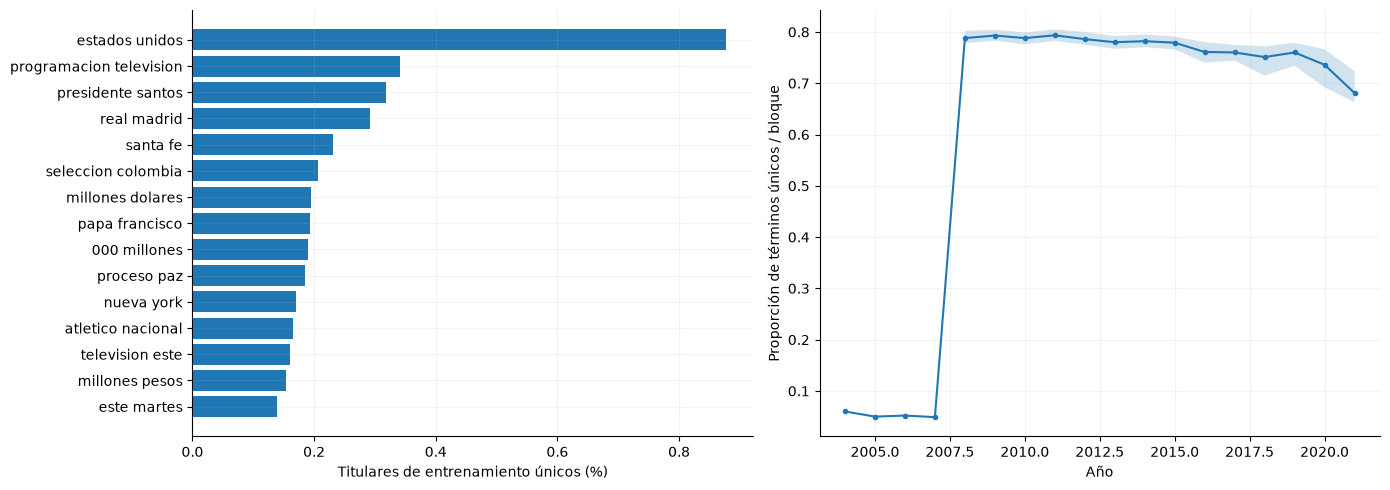

In [7]:
from sklearn.feature_extraction.text import CountVectorizer
ent_texto=texto.loc[texto.periodo=='Entrenamiento'].drop_duplicates(['source','normalizado'])
stop_es=vectorizador.get_stop_words()
bigramador=CountVectorizer(ngram_range=(2,2),binary=True,min_df=10,max_features=3000,
    strip_accents='unicode',stop_words=list(stop_es))
xb=bigramador.fit_transform(ent_texto.titular)
frecuencia_bi=np.asarray(xb.sum(axis=0)).ravel(); terminos_bi=bigramador.get_feature_names_out()
indices=np.argsort(frecuencia_bi)[-15:]
analizador=vectorizador.build_analyzer()
diversidad=[]
for anio,grupo in texto.groupby(texto.fecha.dt.year):
    terminos=[t for s in grupo.titular for t in analizador(s)]
    valores=[len(set(terminos[k:k+1000]))/1000 for k in range(0,len(terminos)-999,1000)]
    if valores: diversidad.append({'anio':anio,'mediana':np.median(valores),'q25':np.quantile(valores,.25),'q75':np.quantile(valores,.75)})
diversidad=pd.DataFrame(diversidad).set_index('anio')
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].barh(terminos_bi[indices],100*frecuencia_bi[indices]/len(ent_texto)); axes[0].set_xlabel('Titulares de entrenamiento únicos (%)')
axes[1].plot(diversidad.index,diversidad.mediana,marker='o',ms=3)
axes[1].fill_between(diversidad.index,diversidad.q25,diversidad.q75,alpha=.2)
axes[1].set(xlabel='Año',ylabel='Proporción de términos únicos / bloque')
fig.tight_layout(); display(fig); plt.close(fig)
bigrama_principal=terminos_bi[indices[-1]]
div_inicio=float(diversidad.mediana.iloc[0]); div_final=float(diversidad.mediana.iloc[-1])


«estados unidos» es el bigrama con mayor presencia entre los candidatos conservados. La diversidad mediana pasa de 0.060 a 0.681 entre el primer y último año representados; las bandas muestran dispersión entre bloques. Los cambios pueden reflejar composición editorial y repetición, además de variaciones del contenido.

## Evolución de tópicos y composición por fuente

Todos los documentos de desarrollo se proyectan con el vocabulario, IDF y seis componentes NMF ajustados en la muestra inicial de entrenamiento. Para comparar componentes se normalizan sus perfiles de términos y se expresa su contribución reconstruida por documento. Los titulares sin representación se contabilizan aparte; sus contribuciones no se imputan a cero.

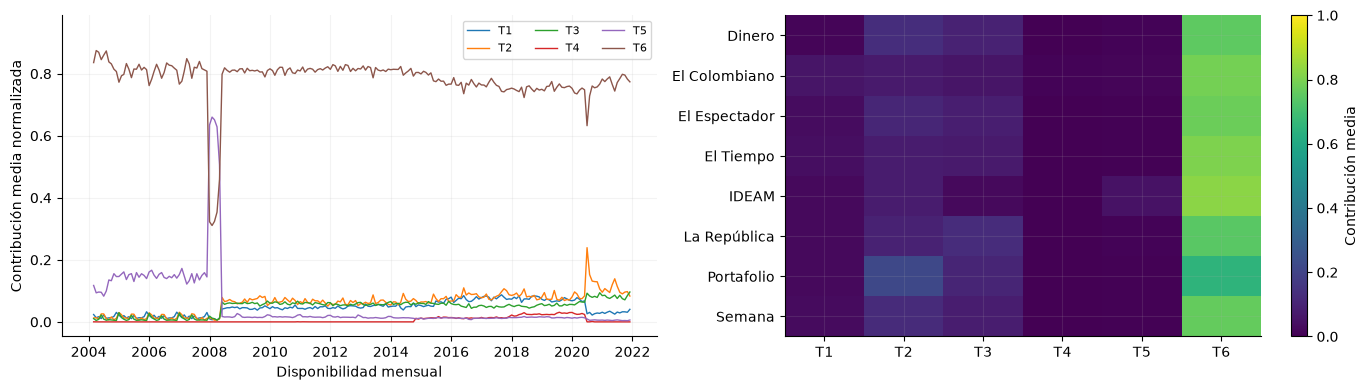

In [8]:
pesos=np.empty((len(texto),nmf.n_components),dtype='float32')
representado=np.zeros(len(texto),dtype=bool); n_tokens=np.zeros(len(texto),dtype='int32')
n_fuera=np.zeros(len(texto),dtype='int32'); vocab=set(vectorizador.vocabulary_)
masa_componentes=nmf.components_.sum(axis=1)
for inicio in range(0,len(texto),20000):
    fin=min(inicio+20000,len(texto)); titulares=texto.titular.iloc[inicio:fin]
    x_lote=vectorizador.transform(titulares); w=nmf.transform(x_lote)
    contribucion=w*masa_componentes[None,:]; total=contribucion.sum(axis=1)
    valido=(x_lote.getnnz(axis=1)>0)&(total>0)
    contribucion=np.divide(contribucion,total[:,None],out=np.full_like(contribucion,np.nan),where=total[:,None]>0)
    pesos[inicio:fin]=contribucion; representado[inicio:fin]=valido
    for j,s in enumerate(titulares,inicio):
        tokens=analizador(s); n_tokens[j]=len(tokens); n_fuera[j]=sum(t not in vocab for t in tokens)
topicos=[f'T{k+1}' for k in range(nmf.n_components)]
proyeccion=pd.DataFrame(pesos,columns=topicos,index=texto.index)
proyeccion.loc[~representado,:]=np.nan
mensual=proyeccion.groupby(texto.mes).mean().reindex(cob_mes.index)
por_fuente=proyeccion.groupby(texto.source).mean()
fig,axes=plt.subplots(1,2,figsize=(14,4))
for topico in topicos: axes[0].plot(mensual.index.to_timestamp(),mensual[topico],label=topico,lw=1)
axes[0].set(xlabel='Disponibilidad mensual',ylabel='Contribución media normalizada'); axes[0].legend(ncol=3,fontsize=8)
im=axes[1].imshow(por_fuente,aspect='auto',vmin=0,vmax=1,cmap='viridis')
axes[1].set(yticks=range(len(por_fuente)),yticklabels=por_fuente.index,xticks=range(len(topicos)),xticklabels=topicos)
fig.colorbar(im,ax=axes[1],label='Contribución media')
fig.tight_layout(); display(fig); plt.close(fig)
cobertura_repr=float(100*representado.mean()); topico_global=proyeccion.mean().idxmax()


El 96.95 % de los titulares tiene representación utilizable; T6 concentra la mayor contribución media. Las curvas muestran evolución del contenido representado y la matriz permite identificar diferencias editoriales. Las interrupciones mensuales indican ausencia de documentos representados; no se interpolan. El volumen y la composición por fuente deben acompañar cualquier interpretación temática.

## Transferencia del vocabulario y estabilidad de los tópicos

La tasa de términos fuera del vocabulario usa los tokens producidos por el mismo analizador de entrenamiento; incluye palabras descartadas por sus umbrales. La divergencia Jensen–Shannon se calcula entre distribuciones de unigramas de entrenamiento y validación en ese vocabulario común. La estabilidad NMF se evalúa con otra inicialización, manteniendo la misma muestra y emparejando componentes por máxima similitud coseno.

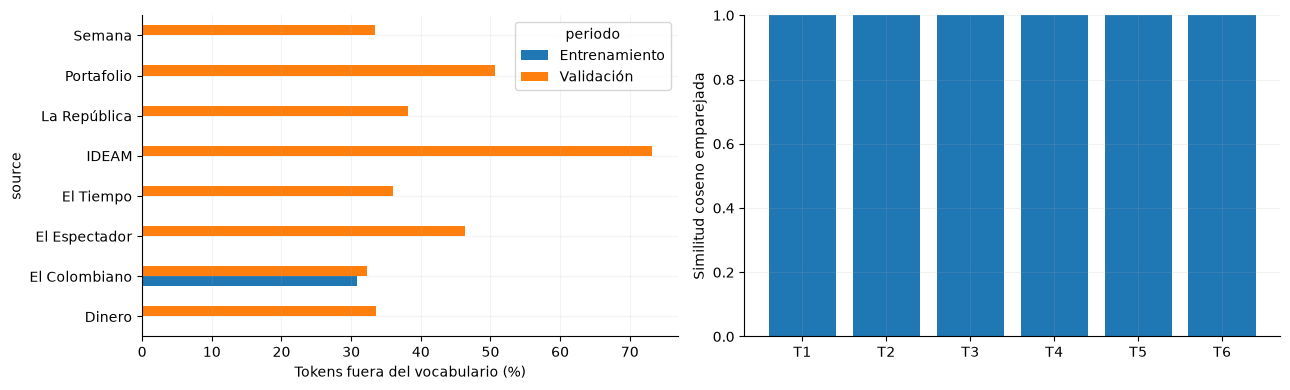

In [9]:
from scipy.spatial.distance import jensenshannon
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.pairwise import cosine_similarity
texto['n_tokens']=n_tokens; texto['n_fuera']=n_fuera; texto['representado']=representado
oov=texto.groupby(['source','periodo'])[['n_tokens','n_fuera']].sum()
tasa=(100*oov.n_fuera/oov.n_tokens.replace(0,np.nan)).unstack('periodo')
conteos={p:np.zeros(len(vocab),dtype=np.float64) for p in ['Entrenamiento','Validación']}
contador=CountVectorizer(vocabulary=vectorizador.vocabulary_,lowercase=vectorizador.lowercase,
    strip_accents=vectorizador.strip_accents,stop_words=list(stop_es),token_pattern=vectorizador.token_pattern)
for periodo,grupo in texto.groupby('periodo'):
    for inicio in range(0,len(grupo),30000):
        conteos[periodo]+=np.asarray(contador.transform(grupo.titular.iloc[inicio:inicio+30000]).sum(axis=0)).ravel()
js=float(jensenshannon(conteos['Entrenamiento'],conteos['Validación'],base=2)**2)
nmf_otro=NMF(n_components=6,init='random',random_state=11038,max_iter=400)
nmf_otro.fit(X)
sim=cosine_similarity(nmf.components_,nmf_otro.components_)
rr,cc=linear_sum_assignment(-sim); estabilidad=sim[rr,cc]
fig,axes=plt.subplots(1,2,figsize=(13,4))
tasa.plot.barh(ax=axes[0]); axes[0].set_xlabel('Tokens fuera del vocabulario (%)')
axes[1].bar([f'T{i+1}' for i in rr],estabilidad); axes[1].set(ylabel='Similitud coseno emparejada',ylim=(0,1))
fig.tight_layout(); display(fig); plt.close(fig)
totales=texto.groupby('periodo')[['n_tokens','n_fuera']].sum()
oov_train=float(100*totales.loc['Entrenamiento','n_fuera']/totales.loc['Entrenamiento','n_tokens'])
oov_val=float(100*totales.loc['Validación','n_fuera']/totales.loc['Validación','n_tokens'])
sim_min=float(estabilidad.min()); sim_media=float(estabilidad.mean())
resumen_texto=dict(documentos=len(texto),oov_train_pct=oov_train,oov_val_pct=oov_val,
    jensen_shannon=js,similitud_media=sim_media,similitud_minima=sim_min,
    repeticion_exacta_pct=dup_exacta,repeticion_normalizada_pct=dup_normal,representados_pct=cobertura_repr)
(ROOT/'results/jbook/texto_resumen.json').write_text(json.dumps(resumen_texto,indent=2),encoding='utf-8')
mensual.to_csv(ROOT/'results/jbook/topicos_mensuales.csv')
por_fuente.to_csv(ROOT/'results/jbook/topicos_por_fuente.csv')
tasa.to_csv(ROOT/'results/jbook/vocabulario_por_fuente.csv')
cob_mes.to_csv(ROOT/'results/jbook/cobertura_texto_mensual.csv')


La tasa global fuera del vocabulario pasa del 30.90 % en entrenamiento al 33.85 % en validación, con divergencia Jensen–Shannon de 0.060. La similitud NMF media es 1.000 y la mínima 1.000, a la precisión mostrada. La primera comparación mide transferencia temporal y entre fuentes; la segunda, sensibilidad a la inicialización dentro de una misma muestra. Una estabilidad alta no prueba relevancia predictiva.

## Cobertura del historial documental por pliegue

Los conteos distinguen todo el historial anterior al año validado de los documentos disponibles durante ese año. No equivalen al número de titulares de cada ventana predictiva, cuya longitud se fijará antes del experimento textual.

In [10]:
cob_folds=[]
for anio in [2018,2019,2020,2021]:
    antes=texto.fecha.dt.year<anio; externo=texto.fecha.dt.year==anio
    cob_folds.append({'año_validado':anio,'historial_documentos':int(antes.sum()),
        'documentos_año_externo':int(externo.sum()),'fuentes_historial':int(texto.loc[antes,'source'].nunique()),
        'fuentes_año_externo':int(texto.loc[externo,'source'].nunique()),
        'días_con_texto_externo':int(texto.loc[externo,'fecha'].dt.normalize().nunique())})
display(pd.DataFrame(cob_folds))


,año_validado,historial_documentos,documentos_año_externo,fuentes_historial,fuentes_año_externo,días_con_texto_externo
0,2018,380541,34225,1,1,365
1,2019,414766,30826,1,1,365
2,2020,445592,18929,1,8,360
3,2021,464521,19768,8,8,364


La tabla permite comprobar si cada año externo dispone de fuentes y días comparables con su historial. Las proyecciones exploratorias usan una representación común ajustada antes de 2018; un futuro entrenamiento textual deberá ajustar su representación dentro del tramo permitido de cada pliegue.